# Завдання 4. Ваги, напрям ребер і висячі вузли

**Пункт 4 ТЗ.** Дослідити вплив ваг і напряму ребер на розподіл релевантності, моделюючи різну «силу» зв'язків, зокрема задаючи різні ваги для різних типів зв'язків; врахувати вузли без вихідних ребер.

Параметри: PPR з α = 0.15, теплове ядро з t = 5.67. Вимірюємо **зміну розподілу**:
- перетин топ-10 і τ_b на топ-50 з базовим варіантом (незваженим або неорієнтованим);
- склад топу за типами вузлів;
- потік імовірності за типами ребер;
- локальність.

Якість відповідей (P@k, nDCG) — у п. 6.

In [1]:
from pathlib import Path
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

from reldiff.api import rank
from reldiff import graphs as G
from reldiff import metaqa as MQ

FIG = Path("../figures"); RES = Path("../results")
ALPHA, T = 0.15, (1 - 0.15) / 0.15
RESOLVE = 1e-10
pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 250)

def prep(s, exclude):
    x = s.drop(index=exclude).to_numpy(dtype=float)
    m = np.abs(x).max()
    x = x / m if m > 0 else x
    x[x < RESOLVE] = 0.0
    return np.round(x, 12)

def topk(x, k):
    pos = np.flatnonzero(x > 0)
    if pos.size <= k: return set(pos)
    thr = np.sort(x[pos])[::-1][k - 1]
    return set(np.flatnonzero(x >= thr))

def overlap(a, b, k=10):
    A, B = topk(a, k), topk(b, k)
    return len(A & B) / min(len(A), len(B)) if A and B else np.nan

def tau50(a, b):
    U = [i for i in sorted(topk(a, 50) | topk(b, 50)) if a[i] > 0 and b[i] > 0]
    if len(U) < 3: return np.nan
    t = kendalltau(a[U], b[U]).statistic
    return 1.0 if np.isnan(t) else t

def compare(s_new, s_base, q):
    # порядок вузлів може різнитися між графами — вирівнюємо за індексом базового варіанта
    s_new = s_new.reindex(s_base.index)
    a, b = prep(s_new, q), prep(s_base, q)
    return dict(перетин_топ10=overlap(a, b), τ_b_топ50=tau50(a, b), L1=np.abs(s_new - s_base).sum())

def locality(s, q, g):
    dd = nx.single_source_shortest_path_length(g.to_undirected(as_view=True) if g.is_directed() else g, q)
    dist = np.array([dd.get(v, np.inf) for v in s.index], dtype=float)
    x = s.to_numpy(dtype=float); p = x[x > 0]; fin = np.isfinite(dist)
    return dict(маса_r_до_2=x[dist <= 2].sum(), сер_відстань=(x[fin] * dist[fin]).sum() / max(x[fin].sum(), 1e-300),
                eff_вузлів=np.exp(-(p * np.log(p)).sum()))

def random_seeds(g, n=20, seed=0):
    r = np.random.default_rng(seed); nodes = list(g.nodes())
    return [nodes[i] for i in r.choice(len(nodes), n, replace=False)]

ER = G.erdos_renyi(1000, 0.01, seed=1)
BA = G.barabasi_albert(1000, 5, seed=5)
SYN = {"ER": ER, "BA": BA}
SEEDS = {k: random_seeds(g) for k, g in SYN.items()}

g_mq, q_mq, _ = MQ.load_processed("../data/metaqa", 500, 0)
r = np.random.default_rng(0)
movies = sorted({t for t in q_mq.topic if "movie" in g_mq.nodes[t]["kinds"]})
people = sorted({t for t in q_mq.topic if {"actor", "director", "writer"} & set(g_mq.nodes[t]["kinds"])
                 and "movie" not in g_mq.nodes[t]["kinds"]})
SEEDS_MQ = list(r.choice(movies, 10, replace=False)) + list(r.choice(people, 10, replace=False))
print(f"Синтетика: ER {ER.number_of_nodes()} вузлів / {ER.number_of_edges()} ребер, BA {BA.number_of_nodes()} / {BA.number_of_edges()}; "
      f"MetaQA {g_mq.number_of_nodes()} / {g_mq.number_of_edges()}")

Синтетика: ER 1000 вузлів / 4962 ребер, BA 1000 / 4975; MetaQA 2957 / 5332


## Завдання 4.1. Напрям ребер

### Синтетика: орієнтовані ER і BA з часткою взаємних ребер ρ

Кожне ребро з імовірністю ρ стає двостороннім, інакше отримує одну дугу випадкового напряму (`orient_with_reciprocity`). Порівнюємо з неорієнтованим графом на тих самих 20 запитах. Стратегія для висячих вузлів — restart для обох моделей (замовчування після рішення за результатами 4.2).

,граф,ρ,модель,частка_висячих,досяжних,перетин_топ10,τ_b_топ50,L1,маса_r_до_2,сер_відстань,eff_вузлів
0,ER,0.000,PPR,0.009,991.000,0.480,-0.070,0.591,0.466,2.261,254.262
1,ER,0.000,теплове ядро,0.009,991.000,0.365,-0.187,0.586,0.199,3.015,669.725
2,ER,0.250,PPR,0.002,997.000,0.550,-0.005,0.482,0.484,2.209,262.644
3,ER,0.250,теплове ядро,0.002,997.000,0.505,-0.071,0.475,0.231,2.946,704.719
4,ER,0.500,PPR,0.003,1000.000,0.690,0.252,0.321,0.491,2.196,287.049
5,ER,0.500,теплове ядро,0.003,1000.000,0.670,0.187,0.325,0.245,2.918,756.513
6,ER,0.750,PPR,0.000,1000.000,0.845,0.450,0.171,0.496,2.182,302.222
7,ER,0.750,теплове ядро,0.000,1000.000,0.830,0.405,0.189,0.254,2.898,787.225
8,ER,1.000,PPR,0.000,1000.000,1.000,1.000,0.000,0.497,2.181,315.893
9,ER,1.000,теплове ядро,0.000,1000.000,1.000,1.000,0.000,0.256,2.895,814.803


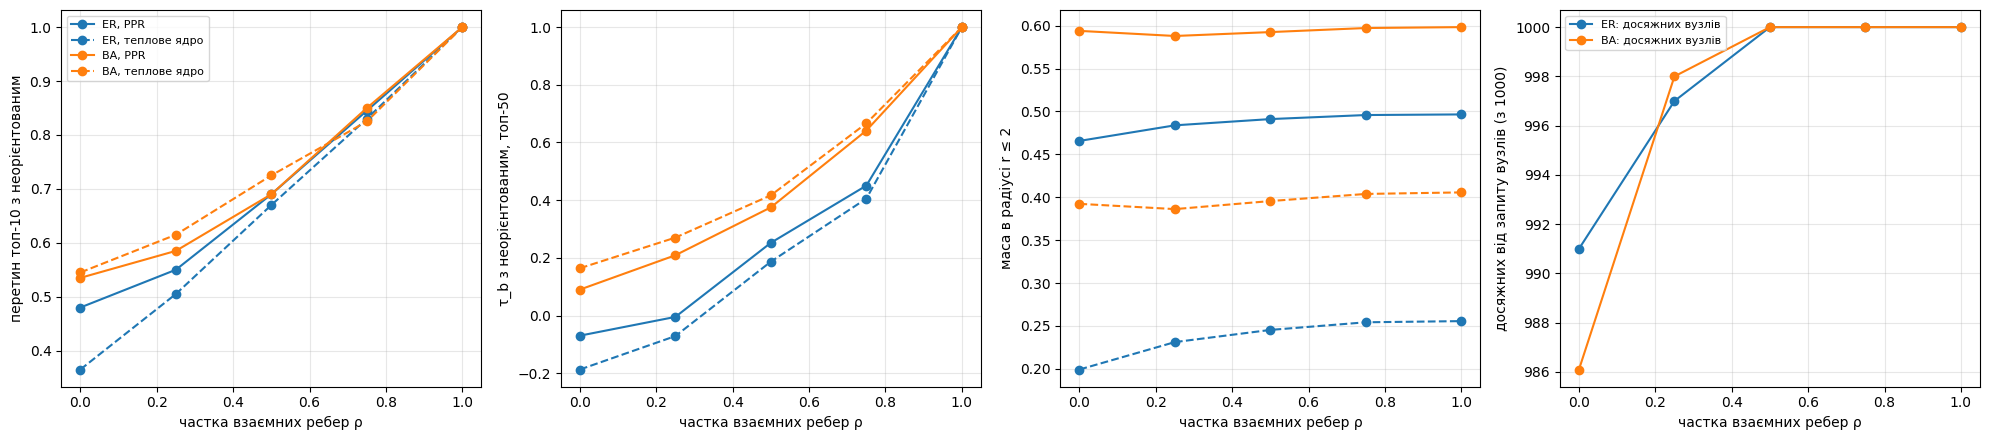

In [2]:
RHOS = [0.0, 0.25, 0.5, 0.75, 1.0]
rows = []
for gname, g in SYN.items():
    for rho in RHOS:
        d = G.orient_with_reciprocity(g, rho, seed=10)
        dang = np.mean([d.out_degree(v) == 0 for v in d])
        for q in SEEDS[gname]:
            reach = len(nx.descendants(d, q)) + 1
            for model, kw in (("PPR", dict(method="ppr", alpha=ALPHA)), ("теплове ядро", dict(method="heat", t=T))):
                s_dir = rank(d, q, **kw); s_und = rank(g, q, **kw)
                rows.append(dict(граф=gname, ρ=rho, модель=model, частка_висячих=dang, досяжних=reach,
                                 **compare(s_dir, s_und, q), **locality(s_dir, q, d)))
dir_syn = pd.DataFrame(rows).groupby(["граф", "ρ", "модель"], sort=False).mean().reset_index()
dir_syn.to_csv(RES / "04_napryam_syntetyka.csv", index=False)
display(dir_syn)

fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
for i, gname in enumerate(SYN):
    for model, ls in (("PPR", "-"), ("теплове ядро", "--")):
        sub = dir_syn[(dir_syn["граф"] == gname) & (dir_syn["модель"] == model)]
        axs[0].plot(sub["ρ"], sub["перетин_топ10"], ls, marker="o", color=f"C{i}", label=f"{gname}, {model}")
        axs[1].plot(sub["ρ"], sub["τ_b_топ50"], ls, marker="o", color=f"C{i}")
        axs[2].plot(sub["ρ"], sub["маса_r_до_2"], ls, marker="o", color=f"C{i}")
    sub = dir_syn[(dir_syn["граф"] == gname) & (dir_syn["модель"] == "PPR")]
    axs[3].plot(sub["ρ"], sub["досяжних"], marker="o", color=f"C{i}", label=f"{gname}: досяжних вузлів")
for ax, lab in zip(axs, ("перетин топ-10 з неорієнтованим", "τ_b з неорієнтованим, топ-50",
                         "маса в радіусі r ≤ 2", "досяжних від запиту вузлів (з 1000)")):
    ax.set_xlabel("частка взаємних ребер ρ"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
axs[0].legend(fontsize=8); axs[3].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_napryam_syntetyka.png", dpi=200); plt.show()

### MetaQA (а): чисто орієнтований граф вироджений

У KB усі дуги ведуть фільм → атрибут. Тому кожен вузол, що не є фільмом, — висячий. Від людини чи тегу маса нікуди не йде: π = s за будь-якої стратегії. Від фільму вона за один крок потрапляє в атрибути і далі не йде.

In [3]:
g_dir, _, _ = MQ.load_processed("../data/metaqa", 500, 0, directed=True)
n_dang = sum(1 for v in g_dir if g_dir.out_degree(v) == 0)
print(f"Орієнтований MetaQA: висячих вузлів {n_dang} з {g_dir.number_of_nodes()} "
      f"({n_dang / g_dir.number_of_nodes():.3f}); фільмів {sum('movie' in k for _, k in g_dir.nodes(data='kinds'))}")
rows = []
for q in SEEDS_MQ:
    kind = "фільм" if "movie" in g_dir.nodes[q]["kinds"] else "людина"
    for model, kw in (("PPR", dict(method="ppr", alpha=ALPHA)), ("теплове ядро", dict(method="heat", t=T))):
        for strat in ("restart", "self_loop"):
            s = rank(g_dir, q, dangling=strat, **kw)
            nb = set(g_dir.successors(q))
            rows.append(dict(запит=kind, модель=model, стратегія=strat, маса_у_запиті=s[q],
                             маса_на_сусідах=s[list(nb)].sum() if nb else 0.0,
                             ненульових_вузлів=int((s > 1e-15).sum())))
degen = pd.DataFrame(rows).groupby(["запит", "модель", "стратегія"], sort=False).mean().reset_index()
display(degen)

Орієнтований MetaQA: висячих вузлів 2457 з 2957 (0.831); фільмів 500


,запит,модель,стратегія,маса_у_запиті,маса_на_сусідах,ненульових_вузлів
0,фільм,PPR,restart,0.541,0.459,13.000
1,фільм,PPR,self_loop,0.150,0.850,13.000
2,фільм,теплове ядро,restart,0.500,0.500,13.000
3,фільм,теплове ядро,self_loop,0.003,0.997,13.000
4,людина,PPR,restart,1.000,0.000,1.000
5,людина,PPR,self_loop,1.000,0.000,1.000
6,людина,теплове ядро,restart,1.000,0.000,1.000
7,людина,теплове ядро,self_loop,1.000,0.000,1.000


### MetaQA (б): асиметричні ваги «вперед/назад»

Граф із дугами в обидва боки: s → o має тип r («вперед»), o → s — тип r⁻¹ («назад»).

**Твердження.** Нехай вага кожної дуги дорівнює w_ij = λ_{c(ij)}·ω_ij, де c(ij) ∈ {вперед, назад} — її напрям, а ω_ij — будь-яка вага, що не залежить від напряму. Якщо в графі немає вузла, з якого виходять дуги обох напрямів, то матриця переходів P = D⁻¹W, а отже π* і u(t), не залежать від λ_вперед і λ_назад.

**Доведення.** Для вузла i з дугами лише одного напряму c маємо d_i = Σ_j λ_c·ω_ij = λ_c·Σ_j ω_ij. Тому P_ij = λ_c·ω_ij/(λ_c·Σ_k ω_ik) = ω_ij/Σ_k ω_ik: λ_c скорочується. Так у кожному рядку, тож P від (λ_вперед, λ_назад) не залежить. π* і u(t) є функціями лише P і s. ∎

**Наслідки для MetaQA:**
- з фільму виходять лише дуги «вперед», з атрибутів і людей — лише дуги «назад»;
- люди в кількох ролях мають лише дуги «назад» (різних типів), тож на спільне відношення не реагують, але реагують на ваги «назад» **за типами**;
- твердження порушує лише вузол, що є одночасно фільмом і об'єктом. У підграфі це «2012» (фільм і рік).

Нижче — чисельна перевірка з «2012» і без нього.

Вузли з дугами обох напрямів: {'з «2012»': ['2012'], 'без «2012»': []}


,варіант,w_f_до_w_b,модель,L1_макс,L1_сер,перетин_топ10_мін,τ_b_мін
0,з «2012»,0.1,PPR,0.0382,0.00506,1,0.914
1,з «2012»,0.1,теплове ядро,0.0561,0.00658,1,0.903
2,з «2012»,0.5,PPR,0.017,0.00226,1,0.984
3,з «2012»,0.5,теплове ядро,0.0253,0.00293,1,0.949
4,з «2012»,1,PPR,0,0,1,1
5,з «2012»,1,теплове ядро,0,0,1,1
6,з «2012»,2,PPR,0.0196,0.0026,1,0.968
7,з «2012»,2,теплове ядро,0.0296,0.00335,1,0.951
8,з «2012»,10,PPR,0.0541,0.00716,1,0.921
9,з «2012»,10,теплове ядро,0.0825,0.00917,1,0.884


Людей у кількох ролях: 174


,вага_starred_назад,модель,перетин_топ10,τ_b_топ50,L1
0,0.100,PPR,1.000,0.979,0.010
1,0.100,теплове ядро,0.995,0.979,0.012
2,0.500,PPR,1.000,0.993,0.002
3,0.500,теплове ядро,1.000,0.993,0.003
4,2.000,PPR,1.000,0.995,0.002
5,2.000,теплове ядро,1.000,0.995,0.002
6,10.000,PPR,1.000,0.990,0.004
7,10.000,теплове ядро,1.000,0.989,0.005


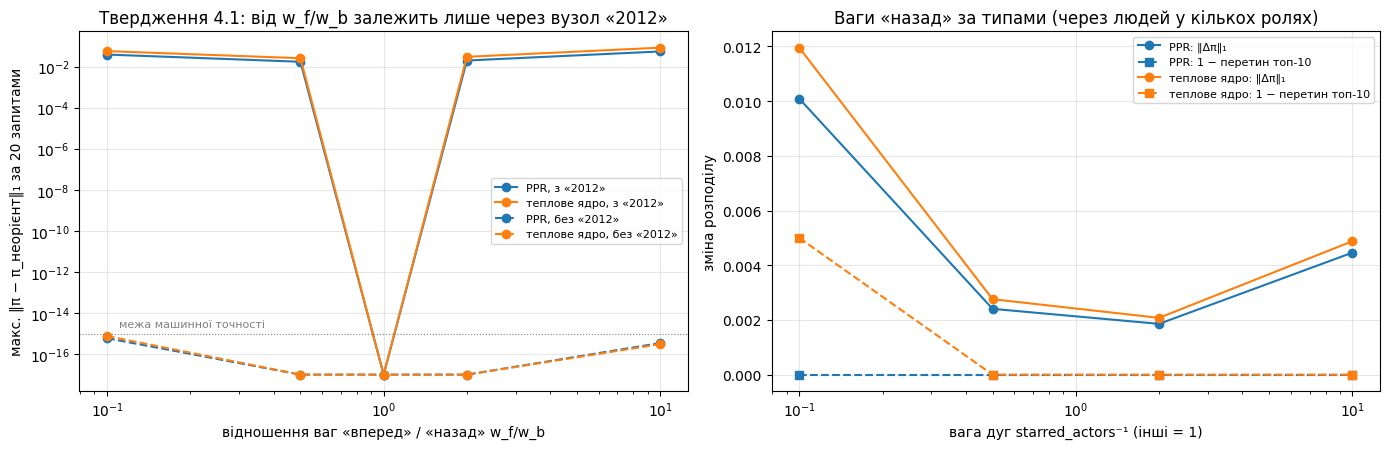

In [4]:
edges = pd.read_csv("../data/metaqa/processed/movies500_seed0/subgraph_edges.csv", dtype=str, keep_default_na=False)
trip = list(edges.itertuples(index=False, name=None))
trip_no2012 = [t for t in trip if "2012" not in (t[0], t[2])]
RELS = sorted(MQ.RELATION_KIND)
BACK = [r + MQ.REVERSE_SUFFIX for r in RELS]
VARIANTS = {"з «2012»": trip, "без «2012»": trip_no2012}
mixed = {name: [v for v, k in MQ.node_kinds(tr).items() if "movie" in k and len(k) > 1] for name, tr in VARIANTS.items()}
print("Вузли з дугами обох напрямів:", mixed)

rows = []
for vname, tr in VARIANTS.items():
    g_bi = MQ.to_graph(tr, bidirected=True); g_un = MQ.to_graph(tr)
    seeds = [q for q in SEEDS_MQ if q in g_un]
    for ratio in (0.1, 0.5, 1.0, 2.0, 10.0):
        tw = {r: ratio for r in RELS} | {b: 1.0 for b in BACK}
        for q in seeds:
            for model, kw in (("PPR", dict(method="ppr", alpha=ALPHA)), ("теплове ядро", dict(method="heat", t=T))):
                rows.append(dict(варіант=vname, w_f_до_w_b=ratio, модель=model,
                                 **compare(rank(g_bi, q, type_weights=tw, **kw), rank(g_un, q, **kw), q)))
prop = pd.DataFrame(rows)
prop_s = prop.groupby(["варіант", "w_f_до_w_b", "модель"], sort=False).agg(
    L1_макс=("L1", "max"), L1_сер=("L1", "mean"), перетин_топ10_мін=("перетин_топ10", "min"), τ_b_мін=("τ_b_топ50", "min")).reset_index()
prop_s.to_csv(RES / "04_metaqa_napryam_tverdzhennya.csv", index=False)
pd.set_option("display.float_format", "{:.3g}".format)
display(prop_s)

# Ваги «назад» за типами: starred_actors⁻¹ = c, решта «назад» = 1, «вперед» = 1 — діють через людей у кількох ролях
g_bi = MQ.to_graph(trip, bidirected=True); g_un = MQ.to_graph(trip)
multi_role = [v for v, k in g_un.nodes(data="kinds") if len({"actor", "director", "writer"} & set(k)) > 1]
print(f"Людей у кількох ролях: {len(multi_role)}")
rows = []
for c in (0.1, 0.5, 2.0, 10.0):
    tw = {r: 1.0 for r in RELS} | {b: 1.0 for b in BACK} | {"starred_actors" + MQ.REVERSE_SUFFIX: c}
    for q in SEEDS_MQ:
        for model, kw in (("PPR", dict(method="ppr", alpha=ALPHA)), ("теплове ядро", dict(method="heat", t=T))):
            rows.append(dict(вага_starred_назад=c, модель=model, **compare(rank(g_bi, q, type_weights=tw, **kw), rank(g_un, q, **kw), q)))
back_t = pd.DataFrame(rows).groupby(["вага_starred_назад", "модель"], sort=False).mean().reset_index()
back_t.to_csv(RES / "04_metaqa_vagy_nazad_za_typamy.csv", index=False)
pd.set_option("display.float_format", "{:.3f}".format)
display(back_t)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
for vname, ls in (("з «2012»", "-"), ("без «2012»", "--")):
    for model, c in (("PPR", "C0"), ("теплове ядро", "C1")):
        sub = prop_s[(prop_s["варіант"] == vname) & (prop_s["модель"] == model)]
        axs[0].semilogy(sub["w_f_до_w_b"], np.maximum(sub["L1_макс"], 1e-17), ls, marker="o", color=c, label=f"{model}, {vname}")
axs[0].set_xscale("log"); axs[0].axhline(1e-15, color="gray", lw=0.8, ls=":")
axs[0].text(0.11, 2e-15, "межа машинної точності", fontsize=8, color="gray")
axs[0].set_xlabel("відношення ваг «вперед» / «назад» w_f/w_b"); axs[0].set_ylabel("макс. ‖π − π_неорієнт‖₁ за 20 запитами")
axs[0].set_title("Твердження 4.1: від w_f/w_b залежить лише через вузол «2012»")
for model, c in (("PPR", "C0"), ("теплове ядро", "C1")):
    sub = back_t[back_t["модель"] == model]
    axs[1].plot(sub["вага_starred_назад"], sub["L1"], "o-", color=c, label=f"{model}: ‖Δπ‖₁")
    axs[1].plot(sub["вага_starred_назад"], 1 - sub["перетин_топ10"], "s--", color=c, label=f"{model}: 1 − перетин топ-10")
axs[1].set_xscale("log"); axs[1].set_xlabel("вага дуг starred_actors⁻¹ (інші = 1)"); axs[1].set_ylabel("зміна розподілу")
axs[1].set_title("Ваги «назад» за типами (через людей у кількох ролях)")
for ax in axs: ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_metaqa_napryam.png", dpi=200); plt.show()

## Завдання 4.2. Висячі вузли: restart проти self_loop

Беремо орієнтовані ER і BA (ρ = 0.5) і видаляємо вихідні дуги в частки f ∈ {0.01, 0.05, 0.1, 0.2} вузлів. Порівнюємо стратегії для обох моделей. Запити, що самі стали висячими, виключаємо, бо від них маса нікуди не йде; їхню кількість показано.

**Теорія (PPR).** Для вузла i, що не є запитом, з вхідним потоком F_i = Σ_{j≠i} π_j·P_ji:
- звичайний вузол: π_i = (1 − α)·F_i;
- висячий вузол із петлею (self_loop): π_i = (1 − α)(F_i + π_i), тобто π_i = (1 − α)·F_i/α;
- висячий вузол зі стратегією restart: π_i = (1 − α)·F_i (його маса йде на s).

Отже, петля підсилює висячий вузол **у 1/α ≈ 6.67 раза** відносно звичайного вузла з тим самим вхідним потоком. Перевіряємо відношення π_i/((1 − α)·F_i).

**Теплове ядро з петлею:** висячий вузол поглинає масу, тож вона там лише накопичується з часом.

In [5]:
def make_dangling(g, f, seed):
    d = G.orient_with_reciprocity(g, 0.5, seed=20)
    r = np.random.default_rng(seed); nodes = list(d.nodes())
    kill = [nodes[i] for i in r.choice(len(nodes), int(round(f * len(nodes))), replace=False)]
    d.remove_edges_from([e for v in kill for e in list(d.out_edges(v))])
    return d

def inflow_ratio(d, s, q, alpha):
    # π_i / ((1 − α)·F_i), F_i = Σ_{j≠i} π_j w_ji / d_j (вхідний потік від інших вузлів)
    outw = {v: sum(dd.get("weight", 1.0) for _, _, dd in d.out_edges(v, data=True)) for v in d}
    F = {v: 0.0 for v in d}
    for j, i, dd in d.edges(data=True):
        if i != j and outw[j] > 0:
            F[i] += s[j] * dd.get("weight", 1.0) / outw[j]
    return {i: s[i] / ((1 - alpha) * F[i]) for i in d if i != q and F[i] > 1e-12}

FS = [0.01, 0.05, 0.1, 0.2]
rows, amp, skipped = [], [], []
for gname, g in SYN.items():
    for f in FS:
        d = make_dangling(g, f, seed=30)
        dang = np.array([d.out_degree(v) == 0 for v in d.nodes()])
        frac = dang.mean()
        # запит, що сам став висячим, вироджений (маса нікуди не йде) — виключаємо і рахуємо
        skipped.append(dict(граф=gname, f=f, виключено_запитів=sum(d.out_degree(q) == 0 for q in SEEDS[gname])))
        for q in SEEDS[gname]:
            if d.out_degree(q) == 0:
                continue
            res = {}
            for model, kw in (("PPR", dict(method="ppr", alpha=ALPHA)), ("теплове ядро", dict(method="heat", t=T))):
                for strat in ("restart", "self_loop"):
                    s = rank(d, q, dangling=strat, **kw)
                    res[(model, strat)] = s
                    x = prep(s, q); dd = np.delete(dang, list(d.nodes()).index(q))
                    T10 = sorted(topk(x, 10))
                    rows.append(dict(граф=gname, f=f, частка_висячих=frac, модель=model, стратегія=strat,
                                     маса_на_висячих=s[dang].sum() - (s[q] if d.out_degree(q) == 0 else 0),
                                     висячих_у_топ10=dd[T10].mean()))
                    if model == "PPR" and f == 0.1:
                        rat = inflow_ratio(d, s, q, ALPHA)
                        for i, v in rat.items():
                            amp.append(dict(граф=gname, стратегія=strat, висячий=d.out_degree(i) == 0, відношення=v))
            for model in ("PPR", "теплове ядро"):
                a, b = prep(res[(model, "restart")], q), prep(res[(model, "self_loop")], q)
                rows.append(dict(граф=gname, f=f, частка_висячих=frac, модель=model, стратегія="перетин restart/self_loop",
                                 перетин_топ10=overlap(a, b)))
dang_t = pd.DataFrame(rows).groupby(["граф", "f", "модель", "стратегія"], sort=False).mean().reset_index()
dang_t.to_csv(RES / "04_visyachi_vuzly.csv", index=False)
print("Запити, що самі стали висячими і виключені:", pd.DataFrame(skipped).to_dict("records"))
display(dang_t)
amp_t = pd.DataFrame(amp).groupby(["граф", "стратегія", "висячий"])["відношення"].agg(["median", "min", "max", "count"]).reset_index()
amp_t.to_csv(RES / "04_pidsylennya_1_alpha.csv", index=False)
pd.set_option("display.float_format", "{:.6f}".format)
print(f"Відношення π_i/((1 − α)F_i), f = 0.1 (теорія: 1 для звичайних і висячих з restart, 1/α = {1 / ALPHA:.6f} для висячих з self_loop):")
display(amp_t)
pd.set_option("display.float_format", "{:.3f}".format)

Запити, що самі стали висячими і виключені: [{'граф': 'ER', 'f': 0.01, 'виключено_запитів': 0}, {'граф': 'ER', 'f': 0.05, 'виключено_запитів': 2}, {'граф': 'ER', 'f': 0.1, 'виключено_запитів': 1}, {'граф': 'ER', 'f': 0.2, 'виключено_запитів': 5}, {'граф': 'BA', 'f': 0.01, 'виключено_запитів': 0}, {'граф': 'BA', 'f': 0.05, 'виключено_запитів': 2}, {'граф': 'BA', 'f': 0.1, 'виключено_запитів': 1}, {'граф': 'BA', 'f': 0.2, 'виключено_запитів': 5}]


,граф,f,модель,стратегія,частка_висячих,маса_на_висячих,висячих_у_топ10,перетин_топ10
0,ER,0.010,PPR,restart,0.011,0.007,0.010,NaN
1,ER,0.010,PPR,self_loop,0.011,0.043,0.110,NaN
2,ER,0.010,теплове ядро,restart,0.011,0.008,0.010,NaN
3,ER,0.010,теплове ядро,self_loop,0.011,0.044,0.140,NaN
4,ER,0.010,PPR,перетин restart/self_loop,0.011,NaN,NaN,0.900
5,ER,0.010,теплове ядро,перетин restart/self_loop,0.011,NaN,NaN,0.855
6,ER,0.050,PPR,restart,0.051,0.032,0.044,NaN
7,ER,0.050,PPR,self_loop,0.051,0.181,0.233,NaN
8,ER,0.050,теплове ядро,restart,0.051,0.041,0.039,NaN
9,ER,0.050,теплове ядро,self_loop,0.051,0.196,0.556,NaN


Відношення π_i/((1 − α)F_i), f = 0.1 (теорія: 1 для звичайних і висячих з restart, 1/α = 6.666667 для висячих з self_loop):


,граф,стратегія,висячий,median,min,max,count
0,BA,restart,False,1.000000,1.000000,1.000000,17062
1,BA,restart,True,1.000000,1.000000,1.000000,1900
2,BA,self_loop,False,1.000000,1.000000,1.000000,17062
3,BA,self_loop,True,6.666667,6.666667,6.666667,1900
4,ER,restart,False,1.000000,1.000000,1.000000,17005
5,ER,restart,True,1.000000,1.000000,1.000000,1919
6,ER,self_loop,False,1.000000,1.000000,1.000000,17005
7,ER,self_loop,True,6.666667,6.666667,6.666667,1919


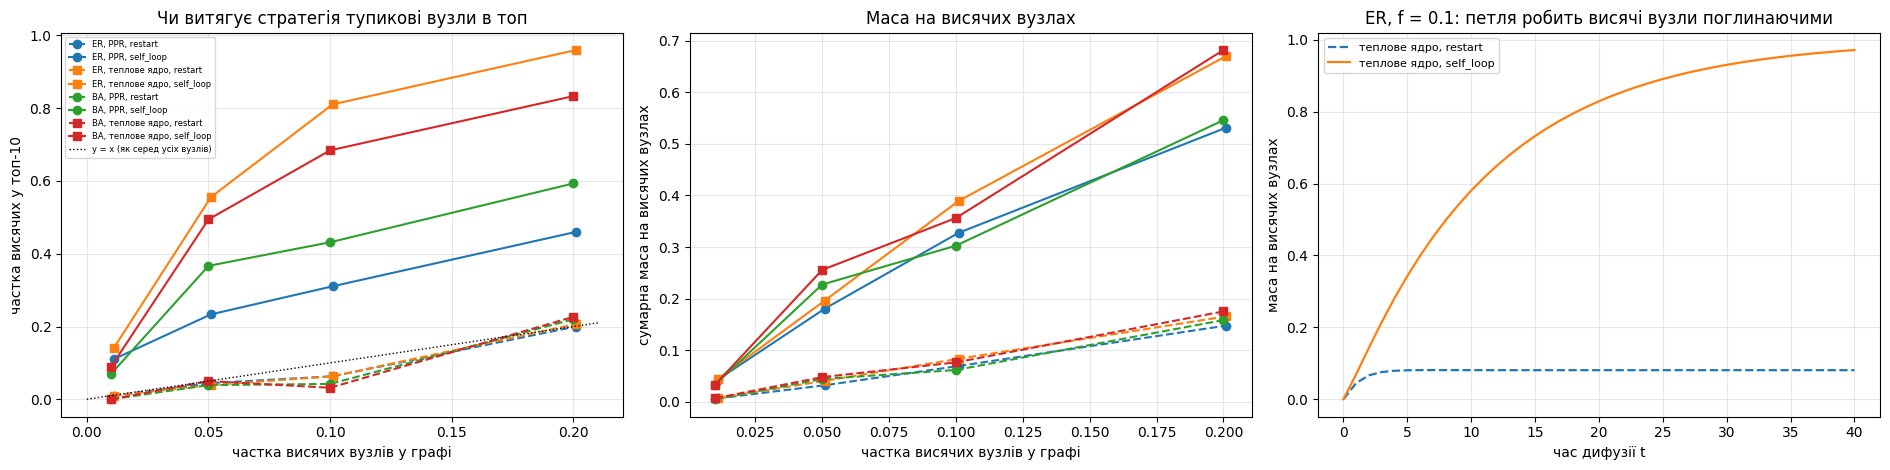

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(19, 4.8))
for i, gname in enumerate(SYN):
    for model, mk in (("PPR", "o"), ("теплове ядро", "s")):
        for strat, ls in (("restart", "--"), ("self_loop", "-")):
            sub = dang_t[(dang_t["граф"] == gname) & (dang_t["модель"] == model) & (dang_t["стратегія"] == strat)]
            axs[0].plot(sub["частка_висячих"], sub["висячих_у_топ10"], ls, marker=mk, color=f"C{2 * i + (model != 'PPR')}",
                        label=f"{gname}, {model}, {strat}")
            axs[1].plot(sub["частка_висячих"], sub["маса_на_висячих"], ls, marker=mk, color=f"C{2 * i + (model != 'PPR')}")
xx = np.linspace(0, 0.21, 10)
axs[0].plot(xx, xx, "k:", lw=1, label="y = x (як серед усіх вузлів)")
axs[0].set_xlabel("частка висячих вузлів у графі"); axs[0].set_ylabel("частка висячих у топ-10")
axs[0].set_title("Чи витягує стратегія тупикові вузли в топ"); axs[0].legend(fontsize=6)
axs[1].set_xlabel("частка висячих вузлів у графі"); axs[1].set_ylabel("сумарна маса на висячих вузлах")
axs[1].set_title("Маса на висячих вузлах")

d = make_dangling(ER, 0.1, seed=30); dang = np.array([d.out_degree(v) == 0 for v in d.nodes()])
ts = np.linspace(0, 40, 41)
for strat, ls in (("restart", "--"), ("self_loop", "-")):
    m = np.mean([[rank(d, q, "heat", t=t, dangling=strat)[dang].sum() for t in ts]
                 for q in [q for q in SEEDS["ER"] if d.out_degree(q) > 0][:10]], axis=0)
    axs[2].plot(ts, m, ls, lw=1.6, label=f"теплове ядро, {strat}")
axs[2].set_xlabel("час дифузії t"); axs[2].set_ylabel("маса на висячих вузлах")
axs[2].set_title("ER, f = 0.1: петля робить висячі вузли поглинаючими")
for ax in axs: ax.grid(alpha=0.3)
axs[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_visyachi_vuzly.png", dpi=200); plt.show()

## Завдання 4.3. Ваги

### Синтетика: логнормальні ваги з різним розкидом σ

Ваги ребер w = exp(σZ − σ²/2) мають середнє 1. Порівнюємо з незваженим графом.

,граф,σ,модель,перетин_топ10,τ_b_топ50,L1,маса_r_до_2,сер_відстань,eff_вузлів
0,ER,0.000,PPR,1.000,1.000,0.000,0.497,2.181,315.893
1,ER,0.000,теплове ядро,1.000,1.000,0.000,0.256,2.895,814.803
2,ER,0.250,PPR,0.880,0.501,0.097,0.499,2.175,309.565
3,ER,0.250,теплове ядро,0.850,0.535,0.098,0.261,2.884,800.880
4,ER,0.500,PPR,0.835,0.329,0.198,0.507,2.156,292.079
5,ER,0.500,теплове ядро,0.700,0.294,0.207,0.275,2.853,758.355
6,ER,1.000,PPR,0.660,0.131,0.416,0.536,2.082,229.669
7,ER,1.000,теплове ядро,0.510,0.025,0.479,0.332,2.725,577.044
8,ER,2.000,PPR,0.410,-0.092,0.857,0.635,1.833,95.897
9,ER,2.000,теплове ядро,0.320,-0.146,1.094,0.506,2.313,177.847


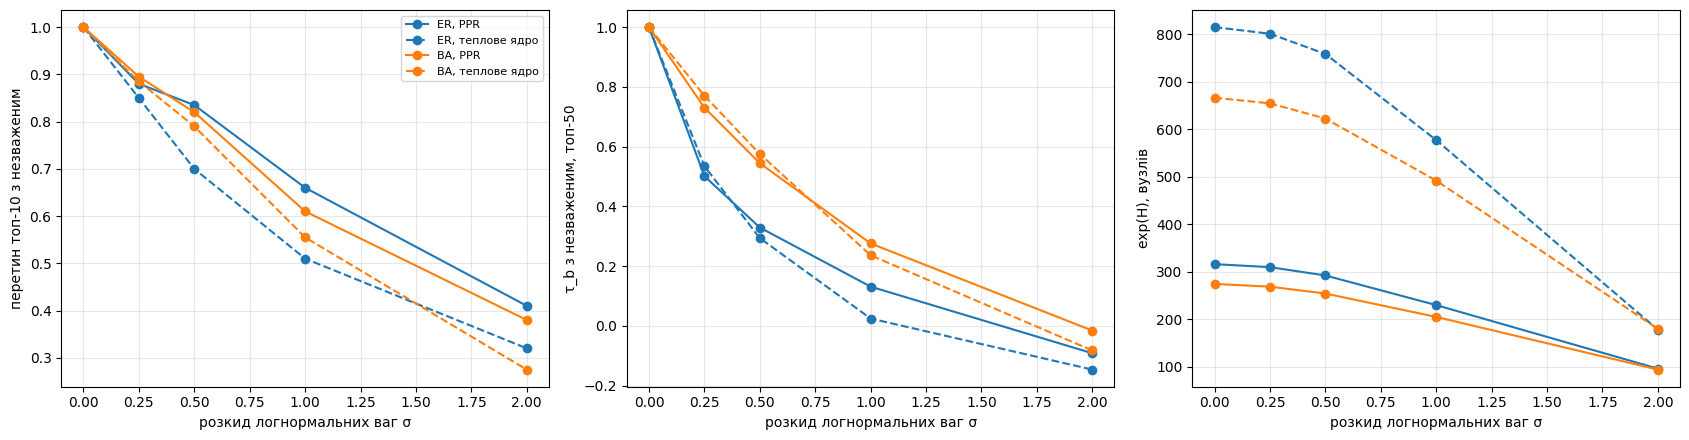

In [7]:
SIG = [0.0, 0.25, 0.5, 1.0, 2.0]
rows = []
for gname, g in SYN.items():
    for sig in SIG:
        gw = G.lognormal_weights(g, sig, seed=40)
        for q in SEEDS[gname]:
            for model, kw in (("PPR", dict(method="ppr", alpha=ALPHA)), ("теплове ядро", dict(method="heat", t=T))):
                rows.append(dict(граф=gname, σ=sig, модель=model, **compare(rank(gw, q, **kw), rank(g, q, **kw), q),
                                 **locality(rank(gw, q, **kw), q, gw)))
w_syn = pd.DataFrame(rows).groupby(["граф", "σ", "модель"], sort=False).mean().reset_index()
w_syn.to_csv(RES / "04_vagy_syntetyka.csv", index=False)
display(w_syn)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for i, gname in enumerate(SYN):
    for model, ls in (("PPR", "-"), ("теплове ядро", "--")):
        sub = w_syn[(w_syn["граф"] == gname) & (w_syn["модель"] == model)]
        axs[0].plot(sub["σ"], sub["перетин_топ10"], ls, marker="o", color=f"C{i}", label=f"{gname}, {model}")
        axs[1].plot(sub["σ"], sub["τ_b_топ50"], ls, marker="o", color=f"C{i}")
        axs[2].plot(sub["σ"], sub["eff_вузлів"], ls, marker="o", color=f"C{i}")
for ax, lab in zip(axs, ("перетин топ-10 з незваженим", "τ_b з незваженим, топ-50", "exp(H), вузлів")):
    ax.set_xlabel("розкид логнормальних ваг σ"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_vagy_syntetyka.png", dpi=200); plt.show()

### MetaQA: сценарії ваг (неорієнтований граф)

1. **Рівні ваги** — базовий сценарій.
2. **«Змістовні зв'язки важчі»:** актор, режисер, сценарист мають вагу r, решта (жанр, рік, мова, теги, imdb) — вагу 1, r ∈ {0.25, 0.5, 1, 2, 4, 8}.
3. **«Послаблені зв'язки до хабів» (графовий аналог IDF):** вага ребра фільм–об'єкт дорівнює d_об'єкта^(−β), β ∈ {0.5, 1}, де d — степінь об'єкта (атрибута або людини) у підграфі. Рідкісний атрибут вважаємо інформативнішим. Ця вага діє з боку фільму: з самого об'єкта всі його ребра однаково послаблені і після нормування рівні.

**Вимірюємо:**
- склад топ-10 за типами;
- потік імовірності за типами ребер: Σ π_i·P_ij по ребрах кожного типу, обидва напрями, частка від загального;
- перетин топ-10 і τ_b з рівними вагами;
- локальність;
- частку хабів у топ-10;
- медіанний ранг Comedy.

In [8]:
PERSON = {"starred_actors", "directed_by", "written_by"}
deg_un = dict(g_mq.degree())
PRIOR = ["movie", "actor", "director", "writer", "genre", "year", "language", "tag", "imdb_rating", "imdb_votes"]
UA = {"movie": "фільм", "actor": "людина", "director": "людина", "writer": "людина", "genre": "жанр", "year": "рік",
      "language": "мова", "tag": "тег", "imdb_rating": "imdb", "imdb_votes": "imdb"}
kind_of = {v: UA[min(k, key=PRIOR.index)] for v, k in g_mq.nodes(data="kinds")}
hub_thr = np.quantile(list(deg_un.values()), 0.99)

def idf_graph(beta):
    h = nx.MultiGraph(); h.add_nodes_from(g_mq.nodes(data=True))
    for s_, r_, o_ in trip:
        h.add_edge(s_, o_, type=r_, weight=deg_un[o_] ** (-beta))
    return h

SCEN = [("рівні", g_mq, {})]
for rr in (0.25, 0.5, 2.0, 4.0, 8.0):
    SCEN.append((f"змістовні r={rr}", g_mq, dict(type_weights={r_: (rr if r_ in PERSON else 1.0) for r_ in RELS})))
for beta in (0.5, 1.0):
    SCEN.append((f"IDF β={beta}", idf_graph(beta), {}))

def flux_by_type(g, s, wdeg, weighted_attr=None, tw=None):
    fl = {}
    for u, v, dd in g.edges(data=True):
        w = tw[dd["type"]] if tw else dd.get("weight", 1.0)
        fl[dd["type"]] = fl.get(dd["type"], 0.0) + s[u] * w / wdeg[u] + s[v] * w / wdeg[v]
    tot = sum(fl.values())
    return {k: v / tot for k, v in fl.items()}

rows, flux_rows, type_rows = [], [], []
base = {}
for sname, gs, extra in SCEN:
    for q in SEEDS_MQ:
        for model, kw in (("PPR", dict(method="ppr", alpha=ALPHA)), ("теплове ядро", dict(method="heat", t=T))):
            s, info = rank(gs, q, return_info=True, **kw, **extra)
            if sname == "рівні":
                base[(q, model)] = s
            cmp = compare(s, base[(q, model)], q)
            x = prep(s, q); nodes_ex = [v for v in s.index if v != q]
            T10 = sorted(topk(x, 10))
            order = np.argsort(-x, kind="stable"); pos = {nodes_ex[i]: k + 1 for k, i in enumerate(order)}
            rows.append(dict(сценарій=sname, модель=model, **cmp, **locality(s, q, gs),
                             хаби_в_топ10=np.mean([deg_un[nodes_ex[i]] >= hub_thr for i in T10]),
                             ранг_Comedy=pos.get("Comedy", np.nan)))
            for kname, c in pd.Series([kind_of[nodes_ex[i]] for i in T10]).value_counts(normalize=True).items():
                type_rows.append(dict(сценарій=sname, модель=model, тип=kname, частка=c / len(SEEDS_MQ)))
            for k_, v_ in flux_by_type(gs, s, info["degrees"], tw=extra.get("type_weights")).items():
                flux_rows.append(dict(сценарій=sname, модель=model, тип_ребра=k_, потік=v_ / len(SEEDS_MQ)))
agg = dict(перетин_топ10=("перетин_топ10", "mean"), τ_b_топ50=("τ_b_топ50", "mean"), L1=("L1", "mean"),
           маса_r_до_2=("маса_r_до_2", "mean"), сер_відстань=("сер_відстань", "mean"), eff_вузлів=("eff_вузлів", "mean"),
           хаби_в_топ10=("хаби_в_топ10", "mean"), медіанний_ранг_Comedy=("ранг_Comedy", "median"))
scen_t = pd.DataFrame(rows).groupby(["сценарій", "модель"], sort=False).agg(**agg).reset_index()
scen_t.to_csv(RES / "04_metaqa_stsenarii.csv", index=False)
display(scen_t)
types_t = pd.DataFrame(type_rows).groupby(["сценарій", "модель", "тип"], sort=False)["частка"].sum().unstack(fill_value=0)
types_t.to_csv(RES / "04_metaqa_typy_top10.csv")
display(types_t)
flux_t = pd.DataFrame(flux_rows).groupby(["сценарій", "модель", "тип_ребра"], sort=False)["потік"].sum().unstack(fill_value=0)
flux_t.to_csv(RES / "04_metaqa_potik_za_typamy.csv")
display(flux_t)

,сценарій,модель,перетин_топ10,τ_b_топ50,L1,маса_r_до_2,сер_відстань,eff_вузлів,хаби_в_топ10,медіанний_ранг_Comedy
0,рівні,PPR,1.000,1.000,0.000,0.628,2.045,135.100,0.193,17.500
1,рівні,теплове ядро,1.000,1.000,0.000,0.503,2.519,284.743,0.214,12.000
2,змістовні r=0.25,PPR,0.765,0.573,0.350,0.589,2.178,147.584,0.255,8.500
3,змістовні r=0.25,теплове ядро,0.710,0.499,0.457,0.432,2.741,329.960,0.298,7.000
4,змістовні r=0.5,PPR,0.885,0.717,0.194,0.605,2.124,147.135,0.200,12.500
5,змістовні r=0.5,теплове ядро,0.815,0.684,0.254,0.461,2.649,325.050,0.258,10.000
6,змістовні r=2.0,PPR,0.825,0.693,0.206,0.657,1.947,111.284,0.160,24.500
7,змістовні r=2.0,теплове ядро,0.790,0.664,0.272,0.552,2.368,214.644,0.160,23.500
8,змістовні r=4.0,PPR,0.750,0.505,0.398,0.687,1.847,84.379,0.140,40.000
9,змістовні r=4.0,теплове ядро,0.670,0.467,0.525,0.599,2.223,145.837,0.140,45.000


тип                            фільм  людина  жанр   тег  imdb   рік  мова
сценарій         модель                                                   
рівні            PPR           0.262   0.320 0.115 0.192 0.005 0.099 0.007
                 теплове ядро  0.326   0.283 0.133 0.154 0.005 0.090 0.008
змістовні r=0.25 PPR           0.287   0.118 0.196 0.277 0.005 0.107 0.010
                 теплове ядро  0.356   0.049 0.233 0.240 0.005 0.109 0.009
змістовні r=0.5  PPR           0.273   0.204 0.140 0.264 0.005 0.106 0.008
                 теплове ядро  0.334   0.139 0.187 0.218 0.005 0.109 0.009
змістовні r=2.0  PPR           0.300   0.460 0.090 0.085 0.005 0.055 0.005
                 теплове ядро  0.350   0.455 0.085 0.055 0.005 0.045 0.005
змістовні r=4.0  PPR           0.350   0.475 0.060 0.070 0.005 0.035 0.005
                 теплове ядро  0.425   0.485 0.050 0.015 0.005 0.015 0.005
змістовні r=8.0  PPR           0.445   0.505 0.020 0.010 0.005 0.015 0.000
                 теплове ядро  0.458   0.522 0.005 0.010 0.000 0.005 0.000
IDF β=0.5        PPR           0.299   0.392 0.040 0.215 0.005 0.050 0.000
                 теплове ядро  0.303   0.406 0.030 0.212 0.005 0.044 0.000
IDF β=1.0        PPR           0.299   0.415 0.020 0.233 0.005 0.029 0.000
                 теплове ядро  0.308   0.424 0.020 0.226 0.005 0.018 0.000

тип_ребра                      directed_by  written_by  has_tags  in_language  release_year  starred_actors  has_genre  has_imdb_votes  has_imdb_rating
сценарій         модель                                                                                                                                
рівні            PPR                 0.101       0.121     0.252        0.010         0.099           0.316      0.095           0.004            0.001
                 теплове ядро        0.101       0.115     0.268        0.013         0.107           0.290      0.102           0.002            0.001
змістовні r=0.25 PPR                 0.044       0.061     0.386        0.017         0.166           0.165      0.153           0.006            0.002
                 теплове ядро        0.042       0.049     0.417        0.021         0.177           0.122      0.167           0.003            0.002
змістовні r=0.5  PPR                 0.069       0.088     0.327        0.014         0.135           0.234      0.127           0.005            0.001
                 теплове ядро        0.068       0.079     0.350        0.017         0.145           0.199      0.137           0.003            0.002
змістовні r=2.0  PPR                 0.133       0.154     0.176        0.007         0.066           0.396      0.064           0.003            0.001
                 теплове ядро        0.134       0.152     0.185        0.009         0.071           0.379      0.069           0.002            0.001
змістовні r=4.0  PPR                 0.161       0.181     0.112        0.004         0.040           0.461      0.039           0.002            0.000
                 теплове ядро        0.162       0.181     0.116        0.005         0.042           0.450      0.042           0.001            0.001
змістовні r=8.0  PPR                 0.180       0.201     0.065        0.002         0.023           0.505      0.022           0.001            0.000
                 теплове ядро        0.181       0.202     0.067        0.003         0.024           0.498      0.024           0.001            0.000
IDF β=0.5        PPR                 0.119       0.143     0.272        0.005         0.057           0.364      0.030           0.011            0.000
                 теплове ядро        0.117       0.141     0.287        0.006         0.060           0.347      0.032           0.010            0.001
IDF β=1.0        PPR                 0.120       0.152     0.273        0.003         0.029           0.395      0.013           0.015            0.000
                 теплове ядро        0.115       0.151     0.287        0.003         0.030           0.385      0.013           0.015            0.000

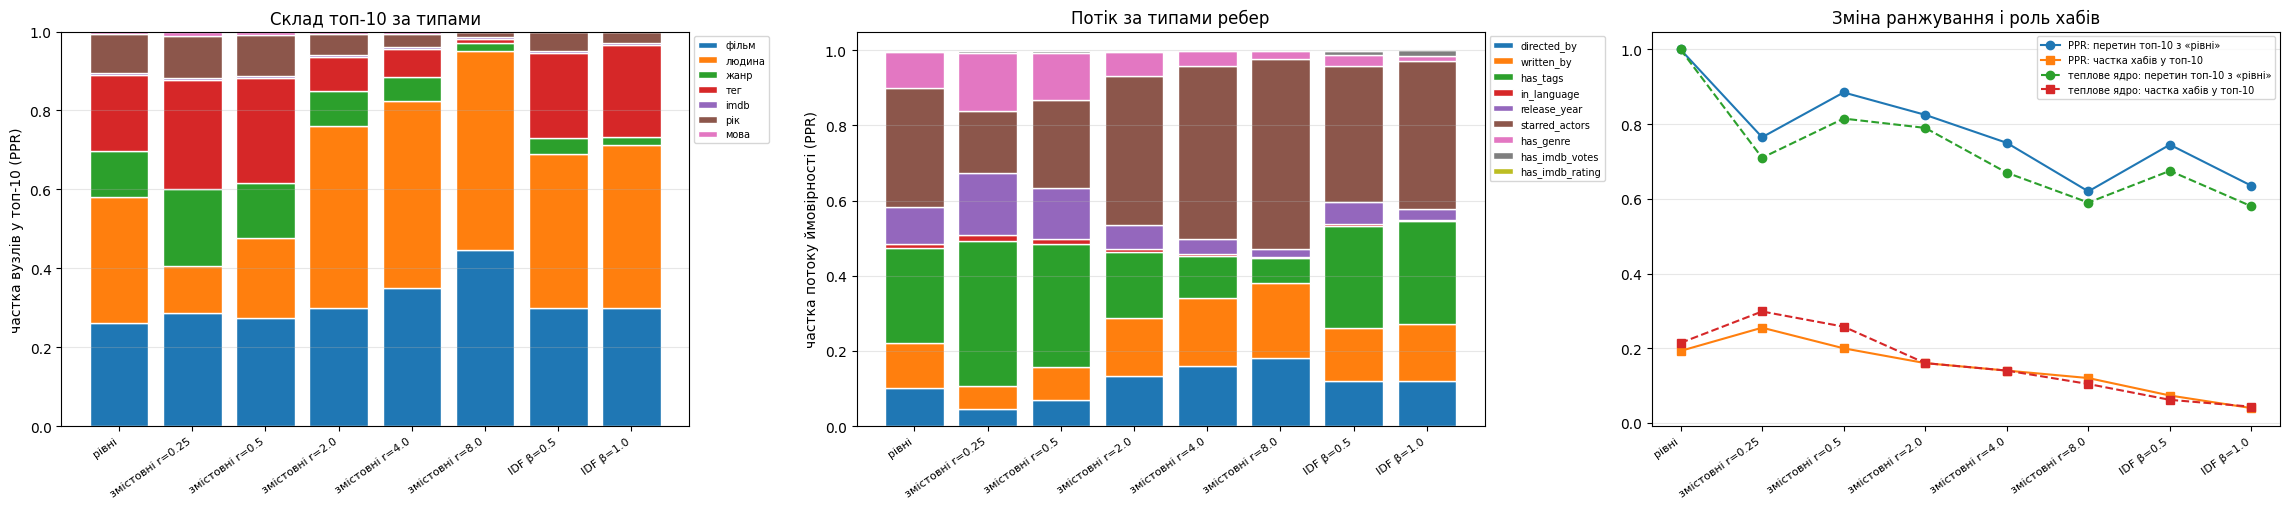

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(23, 5.2))
order = [s for s, _, _ in SCEN]
sub = types_t.xs("PPR", level="модель").reindex(order)
bottom = np.zeros(len(sub))
for c, col in enumerate(sub.columns):
    axs[0].bar(range(len(sub)), sub[col], bottom=bottom, color=f"C{c}", label=col, edgecolor="white", linewidth=1)
    bottom += sub[col].to_numpy()
axs[0].set_xticks(range(len(sub))); axs[0].set_xticklabels(order, rotation=35, ha="right", fontsize=8)
axs[0].set_ylabel("частка вузлів у топ-10 (PPR)"); axs[0].set_title("Склад топ-10 за типами")
axs[0].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fsub = flux_t.xs("PPR", level="модель").reindex(order)
bottom = np.zeros(len(fsub))
for c, col in enumerate(fsub.columns):
    axs[1].bar(range(len(fsub)), fsub[col], bottom=bottom, color=f"C{c}", label=col, edgecolor="white", linewidth=1)
    bottom += fsub[col].to_numpy()
axs[1].set_xticks(range(len(fsub))); axs[1].set_xticklabels(order, rotation=35, ha="right", fontsize=8)
axs[1].set_ylabel("частка потоку ймовірності (PPR)"); axs[1].set_title("Потік за типами ребер")
axs[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
for model, ls in (("PPR", "-"), ("теплове ядро", "--")):
    s2 = scen_t[scen_t["модель"] == model].set_index("сценарій").reindex(order)
    axs[2].plot(range(len(order)), s2["перетин_топ10"], ls, marker="o", label=f"{model}: перетин топ-10 з «рівні»")
    axs[2].plot(range(len(order)), s2["хаби_в_топ10"], ls, marker="s", label=f"{model}: частка хабів у топ-10")
axs[2].set_xticks(range(len(order))); axs[2].set_xticklabels(order, rotation=35, ha="right", fontsize=8)
axs[2].set_title("Зміна ранжування і роль хабів"); axs[2].legend(fontsize=7)
for ax in axs: ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(FIG / "04_metaqa_stsenarii_vag.png", dpi=200); plt.show()

## Висновки

1. **Напрям ребер на синтетиці.** Що менша частка взаємних ребер ρ, то сильніше розподіл відходить від неорієнтованого. На ER перетин топ-10 з неорієнтованим варіантом становить 0.480 (PPR) і 0.365 (теплове ядро) при ρ = 0, 0.690 і 0.670 при ρ = 0.5, 0.845 і 0.830 при ρ = 0.75, і рівно 1 при ρ = 1. На BA при ρ = 0 — 0.535 і 0.545. Усі числа отримано зі стратегією restart для обох моделей. З петлею в тепловому ядрі (старе замовчування) перетин при ρ = 0 був нижчий: 0.240 (ER) і 0.425 (BA). Тобто частина відходу від неорієнтованого варіанта йшла від кількох висячих вузлів (0.9% і 2.1%), а не від самого напряму. Досяжна множина при цьому майже повна (у середньому 991 і 986 вузлів з 1000). Отже, напрям змінює насамперед порядок, а не охоплення. Локальність змінюється мало: маса в радіусі 2 для PPR на ER — 0.466 проти 0.497.
2. **MetaQA і напрям.**
   - Чисто орієнтований граф вироджений: 2457 з 2957 вузлів (83%) висячі. Від людини маса не йде нікуди (π = s, один ненульовий вузол, за обох стратегій і обох моделей). Від фільму вона за один крок застрягає в атрибутах: у середньому 13 ненульових вузлів. Результат тоді визначає стратегія для висячих вузлів: у PPR маса у фільмі-запиті 0.541 з restart проти 0.150 з петлею, у теплового ядра — 0.500 проти 0.003.
   - **Твердження 4.1** (доведено вище): спільне відношення ваг «вперед/назад» скорочується в кожному рядку P, якщо жоден вузол не має дуг обох напрямів. Чисельно без вузла «2012» ‖π − π_неорієнт‖₁ ≤ 7.5·10⁻¹⁶ при w_f/w_b від 0.1 до 10, тобто на рівні округлення. Єдиний вузол «2012» (фільм і рік) дає відхилення до 0.054 (PPR) і 0.083 (теплове ядро), але топ-10 не змінюється (перетин 1, τ_b ≥ 0.884).
   - Ваги «назад» за типами діють лише через 174 людей у кількох ролях, і слабко: ‖Δπ‖₁ ≤ 0.012, перетин топ-10 ≥ 0.995.
   - Отже, у такій схемі графа модель блукання з нормуванням рядків напряму майже не бачить.
3. **Висячі вузли.**
   - Теорія підтверджена точно: оцінка висячого вузла з петлею дорівнює вхідному потоку × (1 − α)/α. Відносно звичайного вузла з тим самим потоком це підсилення в **1/α = 6.666667** раза: виміряне відношення збігається до 6 знаків у всіх 1900 (BA) і 1919 (ER) випадках. Для звичайних вузлів і для restart відношення рівно 1.
   - Через це петля витягує тупикові вузли в топ. На ER при 10% висячих вузлів їхня частка в топ-10 становить 0.311 (PPR) і 0.811 (теплове ядро) з петлею проти 0.063 з restart, тобто не більше за їхню частку в графі. При 20% висячих тепло з петлею дає 0.960.
   - У теплового ядра з петлею висячі вузли поглинають масу: на ER (f = 0.1) на них 0.381 маси при t = 5.67, 0.829 при t = 20 і 0.972 при t = 40. З restart — стабільно 0.081.
   - Перетин топ-10 між стратегіями падає до 0.753 (PPR) і 0.253 (теплове ядро) при f = 0.1.
   - **Рішення:** за результатами 4.2 замовчуванням для обох моделей зроблено restart. На етапі 0 для теплового ядра була петля, але вона зганяє 0.97 маси в тупики при t = 40. Зміна не впливає на ноутбуки 00–03, де всі графи без висячих вузлів, крім перевірки збереження суми в ноутбуці 00, яка дала ті самі числа.
4. **Ваги на синтетиці.** Логнормальний розкид ваг поступово руйнує незважене ранжування. На ER перетин топ-10 (PPR) становить 0.880 при σ = 0.25, 0.660 при σ = 1 і 0.410 при σ = 2, а τ_b на топ-50 падає до ≈ 0 при σ ≥ 1. Сильні ребра концентрують масу: ефективна кількість вузлів зменшується з 316 до 96 при σ = 2.
5. **Сценарії ваг на MetaQA.**
   - «Змістовні зв'язки важчі» (r = 8) переносять потік на людей: частка потоку через starred_actors зростає з 0.316 до 0.505. Топ-10 тоді на 95% складається з фільмів і людей, жанрів у ньому 0.020 замість 0.115, тегів 0.010 замість 0.192. Медіанний ранг Comedy змінюється з 17.5 до 62.5. Зворотний сценарій (r = 0.25) підсилює жанри й теги.
   - «Послаблені зв'язки до хабів» w = d_об'єкта^(−β) — **графовий аналог IDF з інформаційного пошуку**: рідкісний атрибут вважаємо інформативнішим. Він прибирає хаби м'якше, ніж нормування π/d з п. 3. Частка хабів у топ-10 становить 0.073 (β = 0.5) і 0.040 (β = 1) проти 0.193 при рівних вагах. Потік через жанри падає з 0.095 до 0.013, медіанний ранг Comedy змінюється з 17.5 до 343.5. Розподіл стає локальнішим: маса в радіусі 2 зростає з 0.628 до 0.812, ефективна кількість вузлів падає зі 135 до 32. Рідкісні теги лишаються в топі (0.233 при β = 1).
   - Перетин топ-10 з рівними вагами становить 0.62–0.89 (PPR) і 0.58–0.82 (теплове ядро) для всіх сценаріїв, тобто ваги помітно змінюють ранжування. Чи на краще — перевіримо в п. 6.